Indicador Stochastic Oscillator 
Coincide con el resultado obtenido en Tradingview consumiendo Bitcoin/USD de la plataforma Binance  
Intervalo: 1d  
Período: 01/09/2024 - 19/06/2026  

In [1]:
import sys
from datetime import datetime
import pandas_ta_classic as ta

project_root = r"D:\Work\DeepVision\nexora-trading-framework"
if project_root not in sys.path:
    sys.path.append(project_root)


from app.brokers.factory import BrokerFactory, AvailableBrokers
from app.brokers.market_data.provider import DataFormat
from app.visualization.plots import (plot_bos_choch,
    plot_smc_order_blocks, plot_smc_swing_points, plot_smc_strong_weak_hl,
    plot_smc_equal_hl,
)
from app.tradingview.smc_indicator import SMCIndicator
from app.tradingview.types import SMCConfig

In [2]:
binance_provider = BrokerFactory.get_broker(AvailableBrokers.BINANCE, False)

In [19]:
# Available SYMBOLS: BCHUSDT, BTCUSDT, ETHUSDT, BNBUSDT, ADAUSDT, SOLUSDT, XRPUSDT, DOTUSDT, DOGEUSDT, AVAXUSDT, MATICUSDT, EURUSDT
SYMBOL = "BTCUSDT"
start = datetime(2024, 9, 1)
end = datetime(2026, 6, 19)
interval="1d"

monthly_candles = binance_provider.market_data_provider.get_historical_candles(SYMBOL, start=start, end=end, interval=interval, format=DataFormat.OHLCV)
atr_precomputed = ta.atr(monthly_candles["high"], monthly_candles["low"], monthly_candles["close"], 100)

2024-09-01 00:00:00  -  2026-06-19 00:00:00


In [20]:
ohlcv_df = monthly_candles.reset_index(drop=True)
config   = SMCConfig(swing_length=50)
result   = SMCIndicator(config).run(ohlcv_df, precomputed_atr=atr_precomputed)
external = [s for s in result.structure_events if not s.internal]

print(f"Total barras: {len(ohlcv_df)}  |  EQH: {len(result.equal_highs)}  EQL: {len(result.equal_lows)}")

Total barras: 657  |  EQH: 3  EQL: 1


In [21]:
# ATR pre-calentado: descargamos ~6 meses antes del start para evitar NaN en las primeras barras
from datetime import timedelta
import numpy as np

atr_warmup_start = datetime(2024, 9, 1) - timedelta(days=200)
warmup_candles   = binance_provider.market_data_provider.get_historical_candles(
    SYMBOL, start=atr_warmup_start, end=end, interval=interval, format=DataFormat.OHLCV
)
warmup_df = warmup_candles.reset_index(drop=True)

_h = warmup_df["high"].to_numpy(dtype=float)
_l = warmup_df["low"].to_numpy(dtype=float)
_c = warmup_df["close"].to_numpy(dtype=float)
atr_full = SMCIndicator._compute_atr(_h, _l, _c, 200)

# Cola que corresponde exactamente al período de ohlcv_df
atr_precomputed = atr_full[-len(ohlcv_df):]

nan_count = int(np.isnan(atr_precomputed).sum())
print(f"Barras warmup: {len(warmup_df)}  |  ATR ({len(atr_precomputed)} barras)  |  NaN restantes: {nan_count}")

2024-02-14 00:00:00  -  2026-06-19 00:00:00
Barras warmup: 857  |  ATR (657 barras)  |  NaN restantes: 0


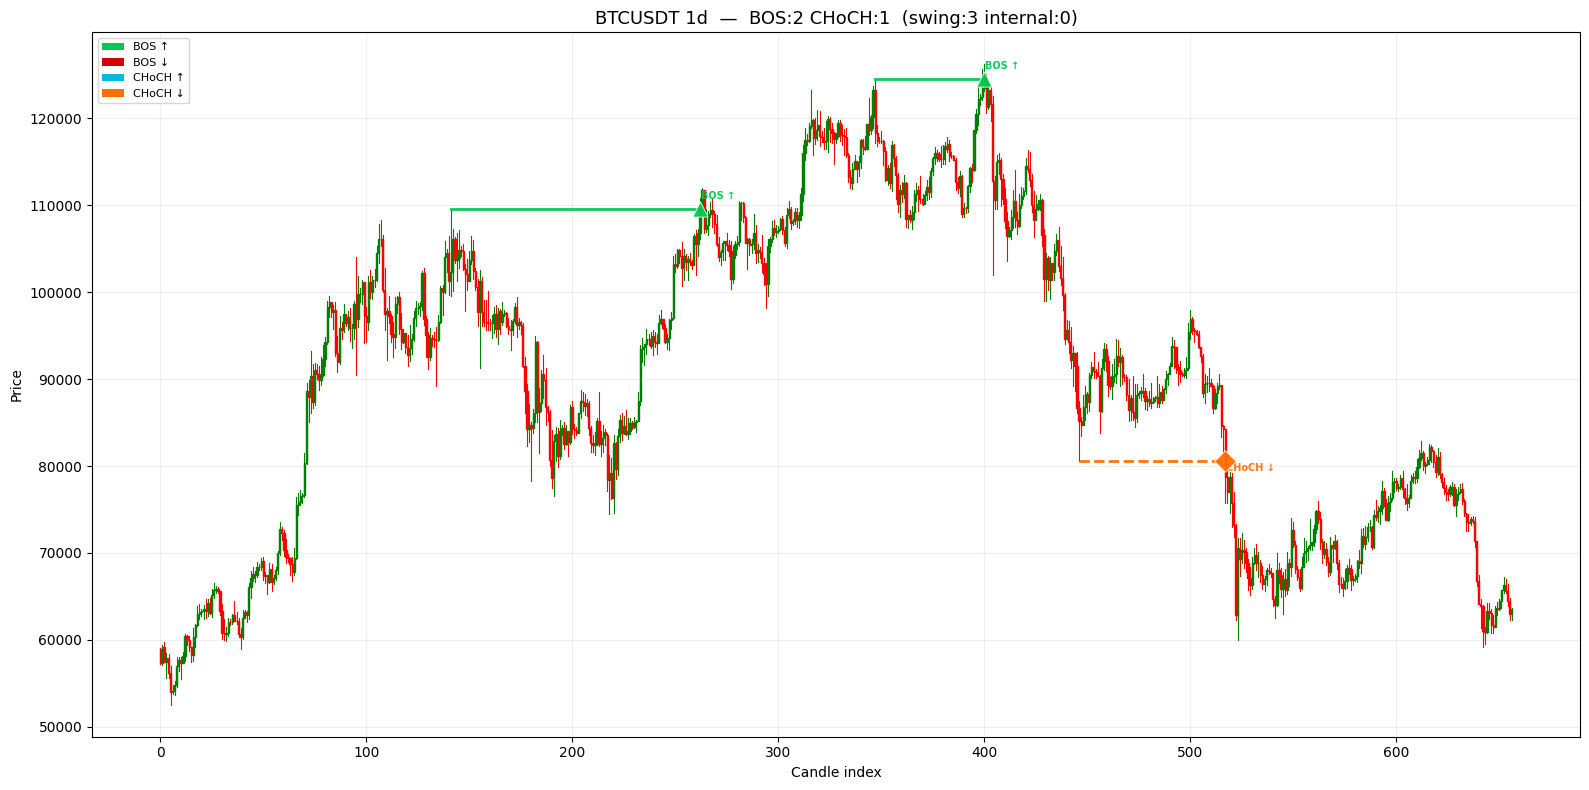

In [22]:
plot_bos_choch(
    df=ohlcv_df,
    events=external,
    title=f"{SYMBOL} {interval}",
)

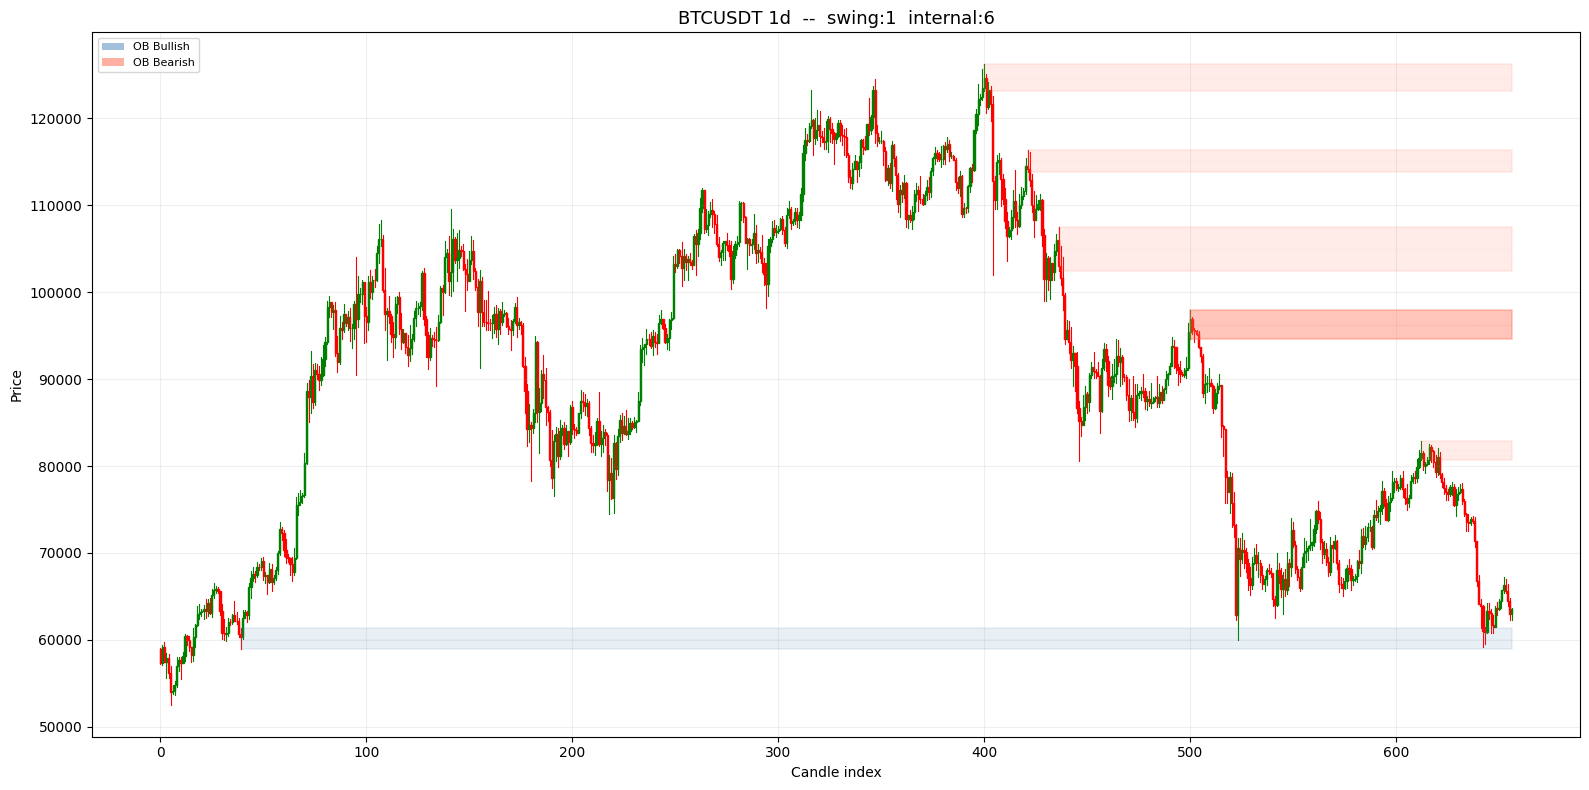

In [23]:
plot_smc_order_blocks(
    df=ohlcv_df,
    swing_obs=result.swing_order_blocks,
    internal_obs=result.internal_order_blocks,
    title=f"{SYMBOL} {interval}",
)

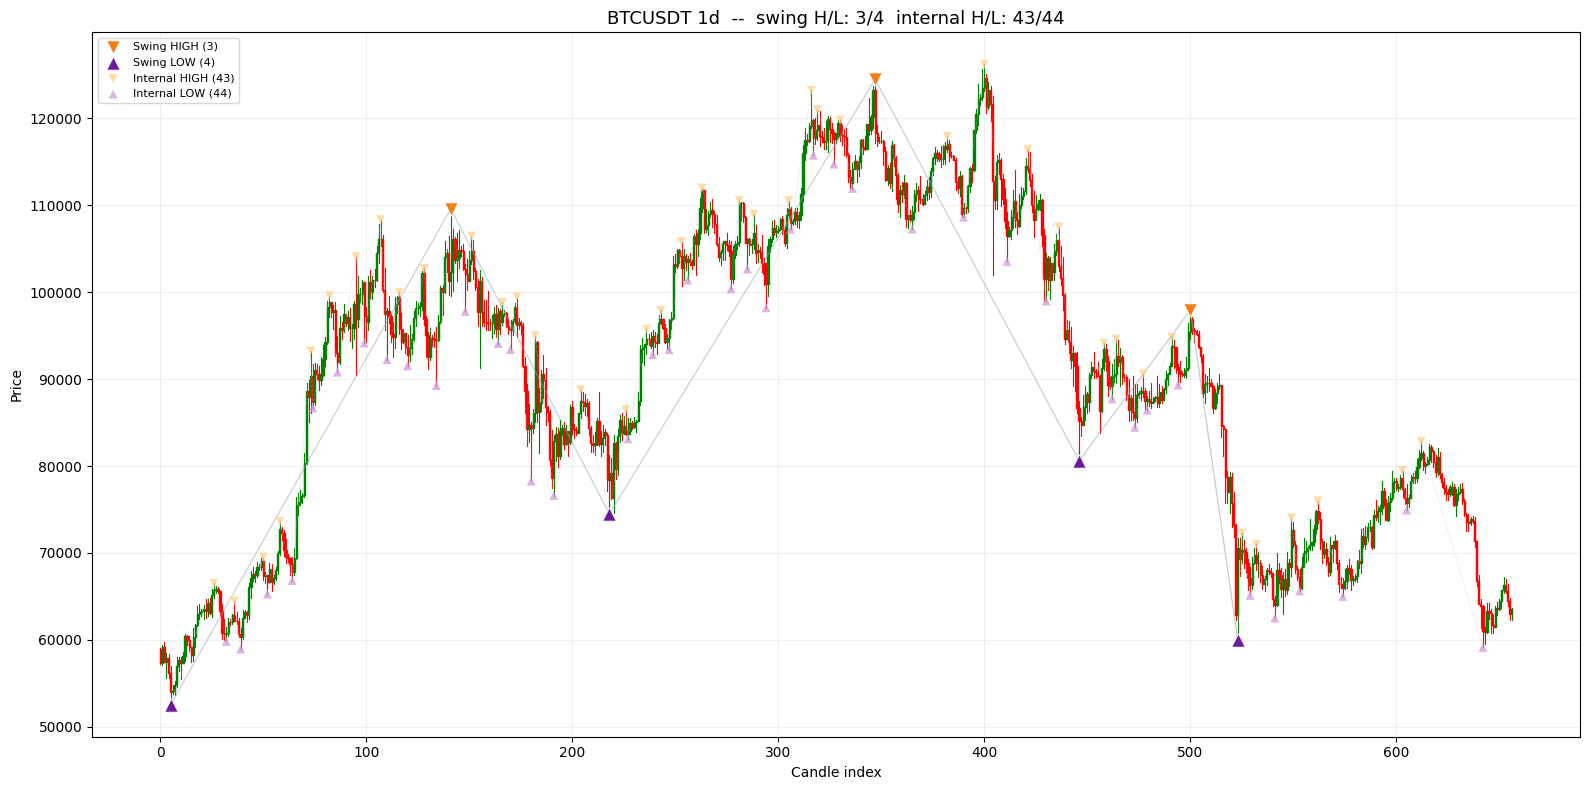

In [24]:
plot_smc_swing_points(
    df=ohlcv_df,
    result=result,
    config=config,
    title=f"{SYMBOL} {interval}",
)

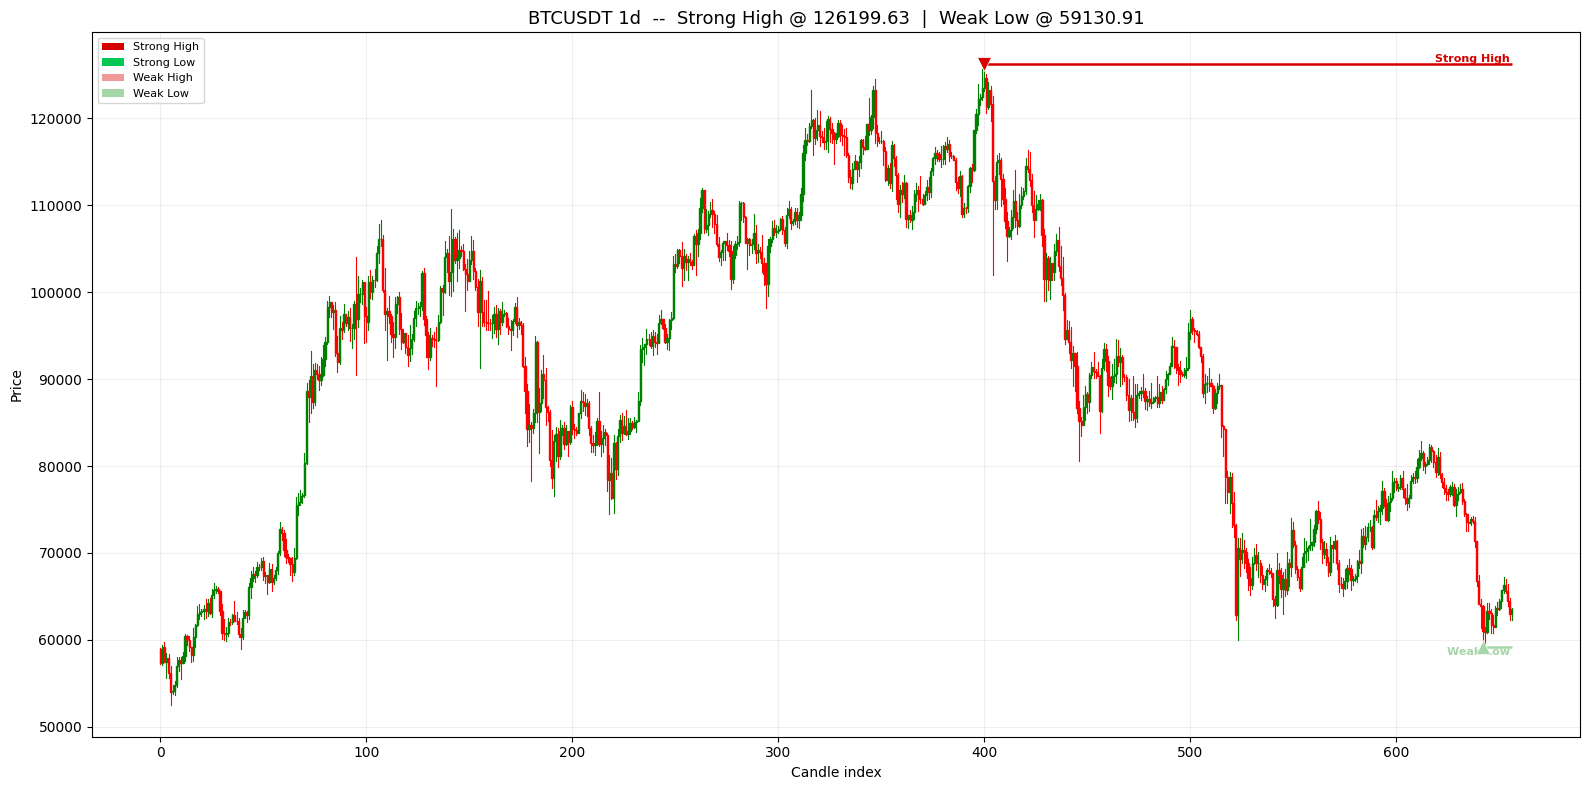

In [25]:
plot_smc_strong_weak_hl(
    df=ohlcv_df,
    result=result,
    swing_only=True,   # False para incluir internal structure
    title=f"{SYMBOL} {interval}",
)

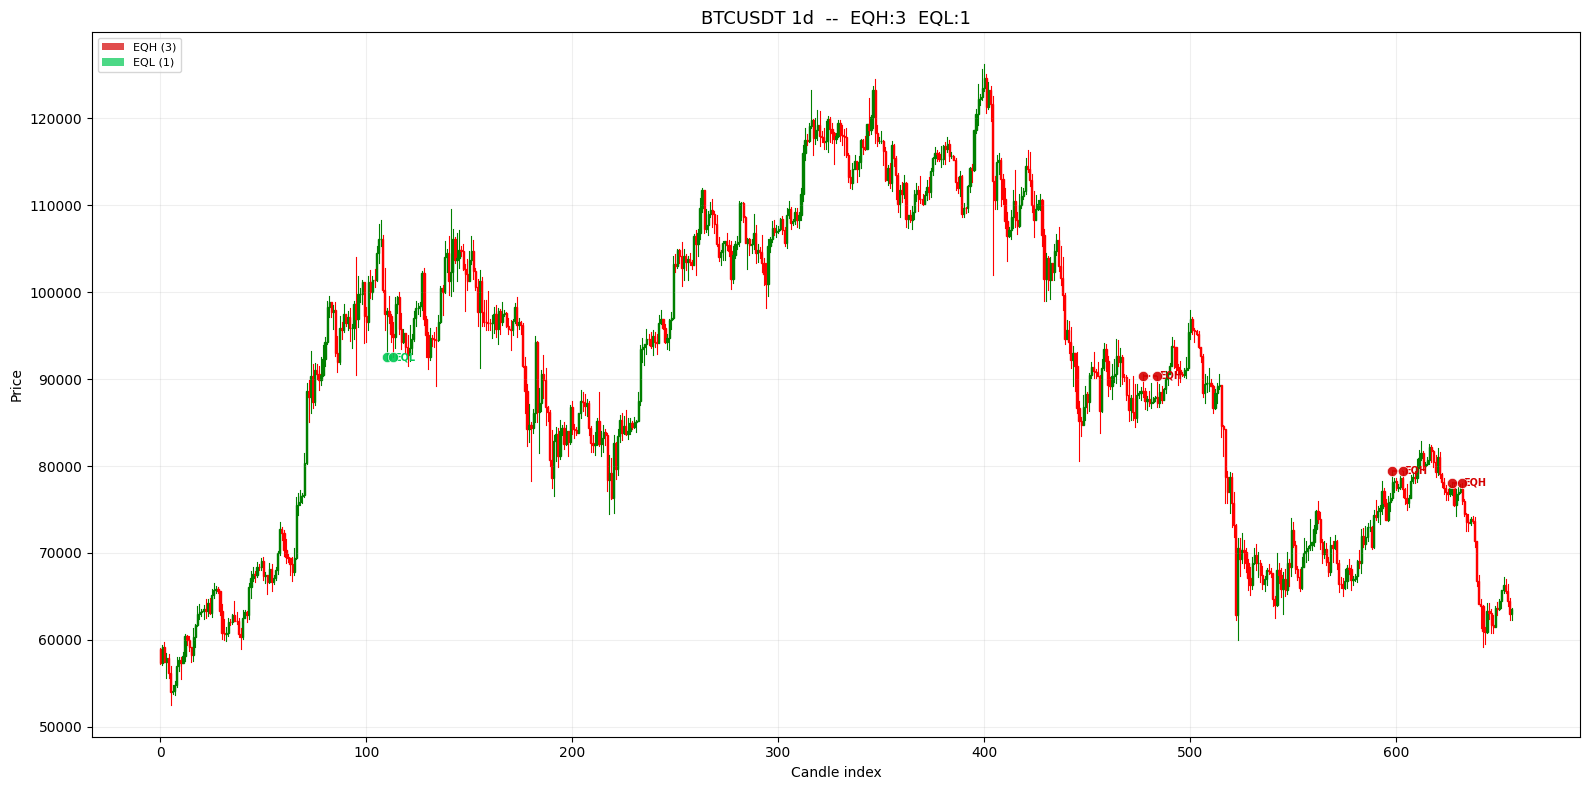

In [26]:
plot_smc_equal_hl(
    df=ohlcv_df,
    result=result,
    title=f"{SYMBOL} {interval}",
)